In [1]:
!pip install mesa networkx scipy

# **Importing Required Libraries**

In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns
from scipy import stats

import mesa

from mesa import Agent
from mesa import Model

from mesa.datacollection import DataCollector

print("Mesa Version :", mesa.__version__)

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

# Graph Style
plt.style.use("ggplot")

Mesa Version : 3.5.1


# **Loading Datasets**

In [3]:
# Government Borrowing
debt = pd.read_csv("series-230626.csv")

# Bond Yield
bond = pd.read_csv("BoE-Database_export.csv")

# World Bank Dataset
macro = pd.read_csv(
    "API_GBR_DS2_en_csv_v2_448313.csv",
    skiprows=4
)

print("Debt Shape :", debt.shape)
print("Bond Shape :", bond.shape)
print("Macro Shape:", macro.shape)

Debt Shape : (574, 2)
Bond Shape : (42, 2)
Macro Shape: (1486, 71)


# **Datsets Overview**

In [4]:
print("\nDebt Dataset")
display(debt.head())

print("\nBond Dataset")
display(bond.head())

print("\nWorld Bank Dataset")
display(macro.head())


Debt Dataset


,Title,"Public sector net borrowing, excluding public sector banks (£ million)"
0,CDID,DZLS
1,Source dataset ID,PUSF
2,PreUnit,£
3,Unit,million
4,Release date,19-06-2026



Bond Dataset


,Date,Value
0,31-12-1984,11.4319
1,31-12-1985,11.1617
2,31-12-1986,10.2052
3,31-12-1987,9.7182
4,31-12-1988,9.7938



World Bank Dataset


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,United Kingdom,GBR,"Unemployment, male (% of male labor force) (mo...",SL.UEM.TOTL.MA.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.624,4.217,3.835,4.760,5.083,3.911,4.335,4.568,5.058,NaN
1,United Kingdom,GBR,"Share of youth not in education, employment or...",SL.UEM.NEET.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,12.261,12.333,12.335,12.607,11.410,11.809,12.802,14.300,14.404,NaN
2,United Kingdom,GBR,"Share of youth not in education, employment or...",SL.UEM.NEET.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,12.267,13.037,12.155,11.916,10.490,11.070,12.122,13.090,13.613,NaN
3,United Kingdom,GBR,"Unemployment with intermediate education, fema...",SL.UEM.INTM.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.650,4.372,3.569,4.483,4.766,4.535,4.975,5.286,5.536,NaN
4,United Kingdom,GBR,Unemployment with advanced education (% of tot...,SL.UEM.ADVN.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.733,2.595,2.344,3.238,3.278,2.346,2.598,2.733,3.367,NaN


## **Datsets Information**

In [5]:
print("\nDebt Info")
debt.info()

print("\nBond Info")
bond.info()

print("\nMacro Info")
macro.info()


Debt Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 2 columns):
 #   Column                                                                  Non-Null Count  Dtype 
---  ------                                                                  --------------  ----- 
 0   Title                                                                   574 non-null    object
 1   Public sector net borrowing, excluding public sector banks (£ million)  501 non-null    object
dtypes: object(2)
memory usage: 9.1+ KB

Bond Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    42 non-null     object 
 1   Value   42 non-null     float64
dtypes: float64(1), object(1)
memory usage: 804.0+ bytes

Macro Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1486 entries, 0 to 1485
Data columns (total 71 columns):
 #   Col

## **Missing vlaue Checking for Each Datasets**

In [6]:
print("\nMissing Values")

print(debt.isnull().sum())

print(bond.isnull().sum())

print(macro.isnull().sum())


Missing Values
Title                                                                      0
Public sector net borrowing, excluding public sector banks (£ million)    73
dtype: int64
Date     0
Value    0
dtype: int64
Country Name         0
Country Code         0
Indicator Name       0
Indicator Code       0
1960              1311
                  ... 
2022               673
2023               738
2024               865
2025              1360
Unnamed: 70       1486
Length: 71, dtype: int64


## **Duplicate Value Checking**

In [7]:
print("\nDuplicates")

print("Debt :", debt.duplicated().sum())

print("Bond :", bond.duplicated().sum())

print("Macro :", macro.duplicated().sum())


Duplicates
Debt : 0
Bond : 0
Macro : 0


# **Data Cleaning**

## **Government Borrowing Data Cleaning**

In [8]:
debt.columns=["Year","Government_Borrowing"]

debt=debt[
    debt["Year"].astype(str).str.match(r"^\d{4}$")
]

debt["Year"]=debt["Year"].astype(int)

debt["Government_Borrowing"]=pd.to_numeric(
    debt["Government_Borrowing"],
    errors="coerce"
)

debt=debt.dropna()

debt.reset_index(drop=True,inplace=True)

display(debt.head())

,Year,Government_Borrowing
0,1997,19381.0
1,1998,3875.0
2,1999,-7654.0
3,2000,-16426.0
4,2001,-3107.0


## **Bond Yield Data Cleaning**

In [9]:
bond.columns=["Date","Bond_Yield"]

bond["Date"]=pd.to_datetime(
    bond["Date"],
    dayfirst=True
)

bond["Year"]=bond["Date"].dt.year

bond_yearly=(
    bond.groupby("Year")
    ["Bond_Yield"]
    .mean()
    .reset_index()
)

display(bond_yearly.head())

,Year,Bond_Yield
0,1984,11.4319
1,1985,11.1617
2,1986,10.2052
3,1987,9.7182
4,1988,9.7938


## **World Bank Indicator Selection**

In [10]:
print("Number of Indicators :", macro["Indicator Name"].nunique())

display(
    macro[["Indicator Name","Indicator Code"]]
    .drop_duplicates()
    .sort_values("Indicator Name")
)

Number of Indicators : 1486


,Indicator Name,Indicator Code
879,ARI treatment (% of children under 5 taken to ...,SH.STA.ARIC.ZS
1087,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.ZS
726,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.RU.ZS
1450,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.UR.ZS
1086,Access to electricity (% of population),EG.ELC.ACCS.ZS
...,...,...
1363,Women who believe a husband is justified in be...,SG.VAW.REFU.ZS
786,Women who were first married by age 15 (% of w...,SP.M15.2024.FE.ZS
168,Women who were first married by age 18 (% of w...,SP.M18.2024.FE.ZS
1357,Women's share of population ages 15+ living wi...,SH.DYN.AIDS.FE.ZS


## **Extracting Required Indicators**

In [11]:
required = [

    "GDP (current US$)",

    "Inflation, consumer prices (annual %)",

    "Unemployment, total (% of total labor force) (modeled ILO estimate)",

    "Population, total",

    "General government final consumption expenditure (% of GDP)"

]

macro = macro[
    macro["Indicator Name"].isin(required)
]

print(macro.shape)

display(macro.head())

(5, 71)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
369,United Kingdom,GBR,"Population, total",SP.POP.TOTL,5.240000e+07,5.280000e+07,5.325000e+07,5.365000e+07,5.400000e+07,5.434805e+07,...,6.596600e+07,6.628900e+07,6.663100e+07,6.674400e+07,6.698400e+07,6.760400e+07,6.849200e+07,6.922600e+07,NaN,NaN
406,United Kingdom,GBR,GDP (current US$),NY.GDP.MKTP.CD,7.323397e+10,7.774197e+10,8.124756e+10,8.656196e+10,9.440756e+10,1.018248e+11,...,2.699118e+12,2.897028e+12,2.875710e+12,2.724001e+12,3.194559e+12,3.181244e+12,3.420797e+12,3.686033e+12,NaN,NaN
985,United Kingdom,GBR,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,1.003576e+00,3.447496e+00,4.196499e+00,2.018544e+00,3.281587e+00,4.773775e+00,...,2.557756e+00,2.292840e+00,1.738105e+00,9.894867e-01,2.518371e+00,7.922049e+00,6.793967e+00,3.271573e+00,NaN,NaN
1008,United Kingdom,GBR,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.501000e+00,4.145000e+00,3.657000e+00,4.472000e+00,4.864000e+00,3.768000e+00,4.025000e+00,4.361000e+00,4.746,NaN
1305,United Kingdom,GBR,General government final consumption expenditu...,NE.CON.GOVT.ZS,1.756838e+01,1.759395e+01,1.791202e+01,1.721476e+01,1.681183e+01,1.760877e+01,...,1.852818e+01,1.837689e+01,1.893473e+01,2.238497e+01,2.190238e+01,2.038754e+01,2.024138e+01,NaN,NaN,NaN


In [12]:
# REQUIRED YEARS

years = [str(i) for i in range(1997,2026)]

columns = [

    "Indicator Name"

] + years

macro = macro[columns]

display(macro.head())

,Indicator Name,1997,1998,1999,2000,2001,2002,2003,2004,2005,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
369,"Population, total",5.831695e+07,5.848714e+07,5.868247e+07,5.889251e+07,5.911967e+07,5.937048e+07,5.964758e+07,5.998790e+07,6.040121e+07,...,6.560700e+07,6.596600e+07,6.628900e+07,6.663100e+07,6.674400e+07,6.698400e+07,6.760400e+07,6.849200e+07,6.922600e+07,NaN
406,GDP (current US$),1.569317e+12,1.660821e+12,1.693459e+12,1.671598e+12,1.656171e+12,1.790537e+12,2.061228e+12,2.429775e+12,2.551362e+12,...,2.706808e+12,2.699118e+12,2.897028e+12,2.875710e+12,2.724001e+12,3.194559e+12,3.181244e+12,3.420797e+12,3.686033e+12,NaN
985,"Inflation, consumer prices (annual %)",2.201143e+00,1.820562e+00,1.752951e+00,1.182956e+00,1.532350e+00,1.520402e+00,1.376500e+00,1.390398e+00,2.089136e+00,...,1.008417e+00,2.557756e+00,2.292840e+00,1.738105e+00,9.894867e-01,2.518371e+00,7.922049e+00,6.793967e+00,3.271573e+00,NaN
1008,"Unemployment, total (% of total labor force) (...",7.072000e+00,6.198000e+00,6.042000e+00,5.558000e+00,4.696000e+00,5.037000e+00,4.807000e+00,4.594000e+00,4.884000e+00,...,4.909000e+00,4.501000e+00,4.145000e+00,3.657000e+00,4.472000e+00,4.864000e+00,3.768000e+00,4.025000e+00,4.361000e+00,4.746
1305,General government final consumption expenditu...,1.595678e+01,1.597092e+01,1.639835e+01,1.658054e+01,1.719737e+01,1.809005e+01,1.877597e+01,1.933416e+01,1.953459e+01,...,1.909261e+01,1.852818e+01,1.837689e+01,1.893473e+01,2.238497e+01,2.190238e+01,2.038754e+01,2.024138e+01,NaN,NaN


## **Transpose Dataset**

In [13]:
macro = macro.set_index("Indicator Name")

macro = macro.T

macro.reset_index(inplace=True)

macro.rename(
    columns={"index":"Year"},
    inplace=True
)

display(macro.head())

Indicator Name,Year,"Population, total",GDP (current US$),"Inflation, consumer prices (annual %)","Unemployment, total (% of total labor force) (modeled ILO estimate)",General government final consumption expenditure (% of GDP)
0,1997,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,59119673.0,1.656171e+12,1.532350,4.696,17.197373


## **Renaming Columns**

In [14]:
macro.columns = [

    "Year",

    "GDP",

    "Inflation",

    "Unemployment",

    "Population",

    "Government_Expenditure"

]

display(macro.head())

,Year,GDP,Inflation,Unemployment,Population,Government_Expenditure
0,1997,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,59119673.0,1.656171e+12,1.532350,4.696,17.197373


# **Converting data**

In [15]:
macro["Year"] = macro["Year"].astype(int)

for col in macro.columns[1:]:

    macro[col] = pd.to_numeric(

        macro[col],

        errors="coerce"

    )

print(macro.info())

display(macro.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    29 non-null     int64  
 1   GDP                     28 non-null     float64
 2   Inflation               28 non-null     float64
 3   Unemployment            28 non-null     float64
 4   Population              29 non-null     float64
 5   Government_Expenditure  27 non-null     float64
dtypes: float64(5), int64(1)
memory usage: 1.5 KB
None


,Year,GDP,Inflation,Unemployment,Population,Government_Expenditure
0,1997,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,59119673.0,1.656171e+12,1.532350,4.696,17.197373


## **Handling Missing Values**

In [16]:
print(macro.isnull().sum())

macro = macro.fillna(method="ffill")

macro = macro.fillna(method="bfill")

print(macro.isnull().sum())

Year                      0
GDP                       1
Inflation                 1
Unemployment              1
Population                0
Government_Expenditure    2
dtype: int64
Year                      0
GDP                       0
Inflation                 0
Unemployment              0
Population                0
Government_Expenditure    0
dtype: int64


# **Merging all Three datasets**

In [17]:
master = debt.merge(

    bond_yearly,

    on="Year",

    how="inner"

)

master = master.merge(

    macro,

    on="Year",

    how="inner"

)

print(master.shape)

display(master.head())

display(master.tail())

(29, 8)


,Year,Government_Borrowing,Bond_Yield,GDP,Inflation,Unemployment,Population,Government_Expenditure
0,1997,19381.0,7.0491,58316954.0,1.569317e+12,2.201143,7.072,15.956784
1,1998,3875.0,5.5465,58487141.0,1.660821e+12,1.820562,6.198,15.970918
2,1999,-7654.0,5.1028,58682466.0,1.693459e+12,1.752951,6.042,16.398354
3,2000,-16426.0,5.3289,58892514.0,1.671598e+12,1.182956,5.558,16.580539
4,2001,-3107.0,4.9279,59119673.0,1.656171e+12,1.532350,4.696,17.197373


,Year,Government_Borrowing,Bond_Yield,GDP,Inflation,Unemployment,Population,Government_Expenditure
24,2021,161122.0,0.7898,66984000.0,3.194559e+12,2.518371,4.864,21.902377
25,2022,108131.0,2.4532,67604000.0,3.181244e+12,7.922049,3.768,20.387540
26,2023,143576.0,4.0692,68492000.0,3.420797e+12,6.793967,4.025,20.241381
27,2024,152004.0,4.1430,69226000.0,3.686033e+12,3.271573,4.361,20.241381
28,2025,147593.0,4.5833,69226000.0,3.686033e+12,3.271573,4.746,20.241381


## **Saving Merging Final Dataset**

In [18]:
master.to_csv("master_dataset.csv", index=False)

## **Dtaset Information**

In [19]:
print(master.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    29 non-null     int64  
 1   Government_Borrowing    29 non-null     float64
 2   Bond_Yield              29 non-null     float64
 3   GDP                     29 non-null     float64
 4   Inflation               29 non-null     float64
 5   Unemployment            29 non-null     float64
 6   Population              29 non-null     float64
 7   Government_Expenditure  29 non-null     float64
dtypes: float64(7), int64(1)
memory usage: 1.9 KB
None


In [20]:
master.describe()

,Year,Government_Borrowing,Bond_Yield,GDP,Inflation,Unemployment,Population,Government_Expenditure
count,29.000000,29.000000,29.000000,2.900000e+01,2.900000e+01,29.000000,29.000000,29.000000
mean,2011.000000,82766.000000,3.492731,6.329347e+07,2.623254e+12,2.434094,5.544379,19.367963
std,8.514693,65074.054079,1.723143,3.521786e+06,6.049423e+11,1.584726,1.371163,1.720942
min,1997.000000,-16426.000000,0.374100,5.831695e+07,1.569317e+12,0.368047,3.657000,15.956784
25%,2004.000000,43613.000000,1.916200,5.998790e+07,2.429358e+12,1.520402,4.594000,18.528177
50%,2011.000000,67828.000000,4.069200,6.325881e+07,2.719558e+12,2.201143,5.037000,19.592725
75%,2018.000000,130512.000000,4.880600,6.628900e+07,2.945580e+12,2.557756,6.198000,20.270350
max,2025.000000,269984.000000,7.049100,6.922600e+07,3.686033e+12,7.922049,8.279000,22.384973


# **Exploratory Data Analysis (EDA)**

## **Correlation Matrix**

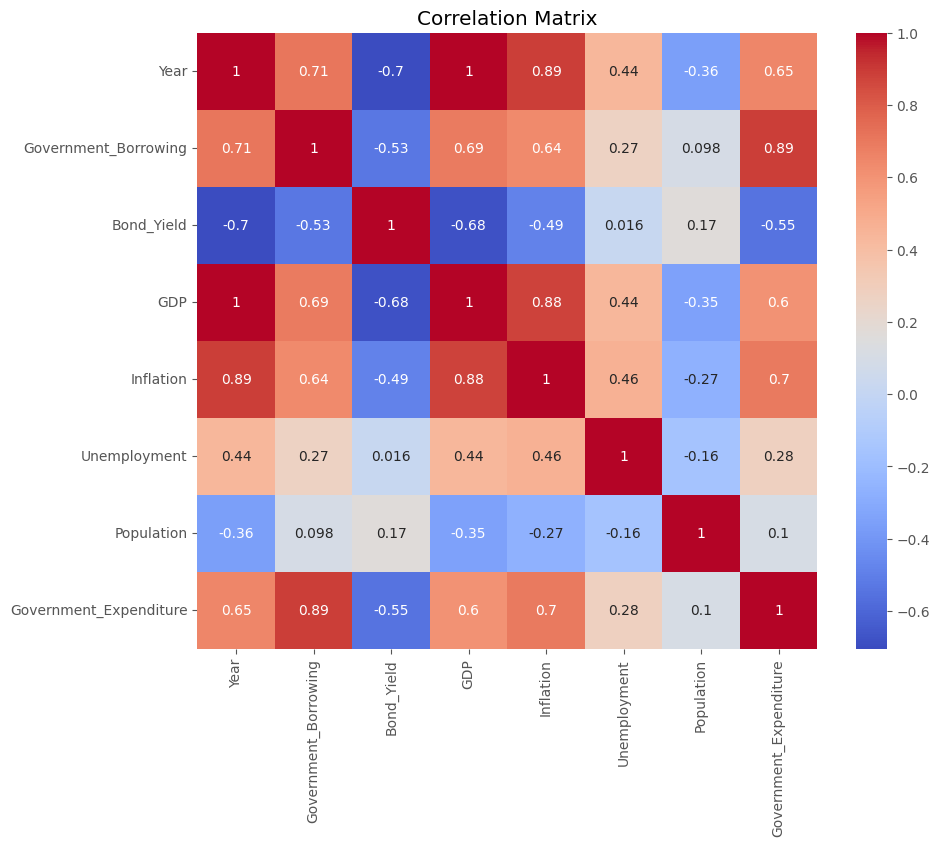

In [21]:
plt.figure(figsize=(10,8))

sns.heatmap(
    master.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

## **Government Borrowing Trend**

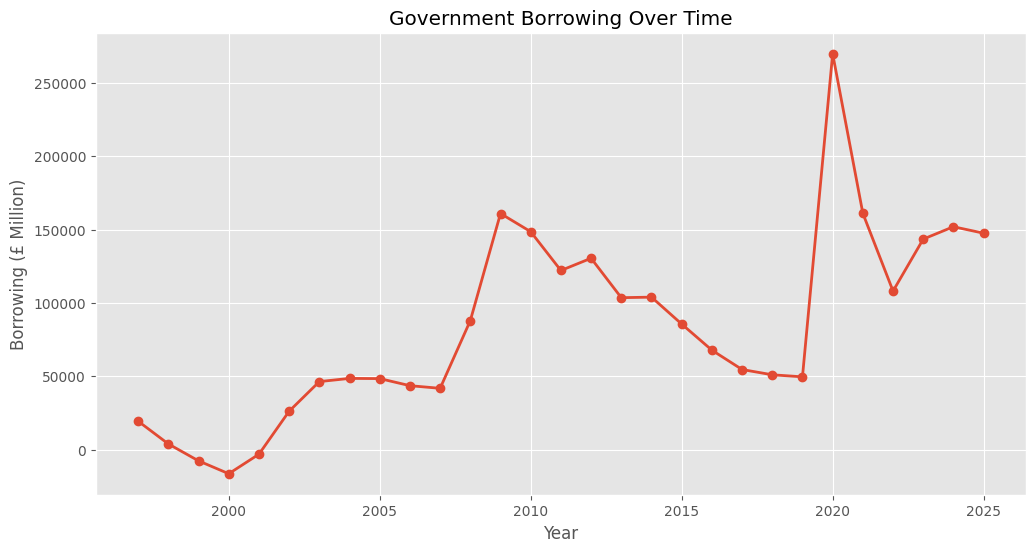

In [22]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Government_Borrowing"],
    marker="o",
    linewidth=2
)

plt.title("Government Borrowing Over Time")

plt.xlabel("Year")

plt.ylabel("Borrowing (£ Million)")

plt.grid(True)

plt.show()

## **Bond Yield Trend**


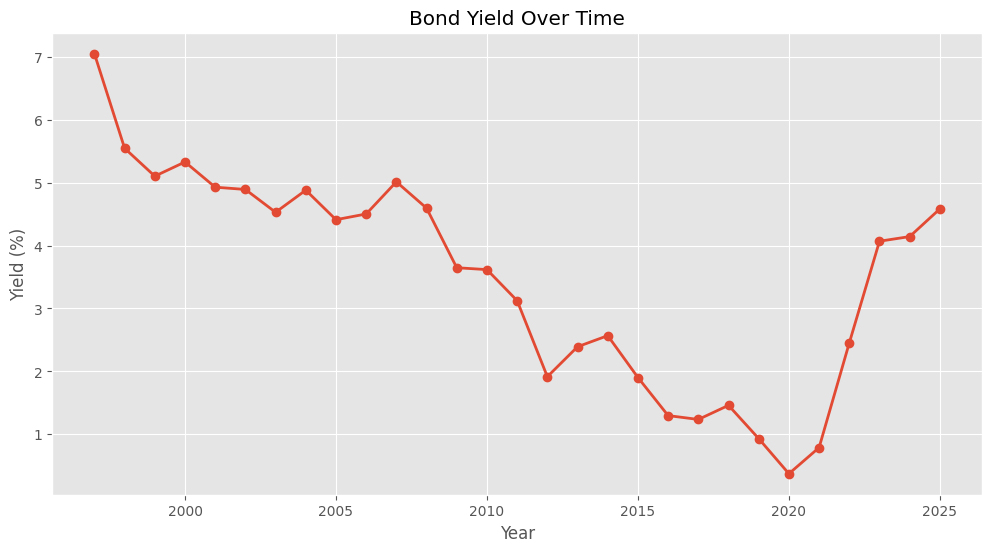

In [23]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Bond_Yield"],
    marker="o",
    linewidth=2
)

plt.title("Bond Yield Over Time")

plt.xlabel("Year")

plt.ylabel("Yield (%)")

plt.grid(True)

plt.show()

## **GDP Trend**

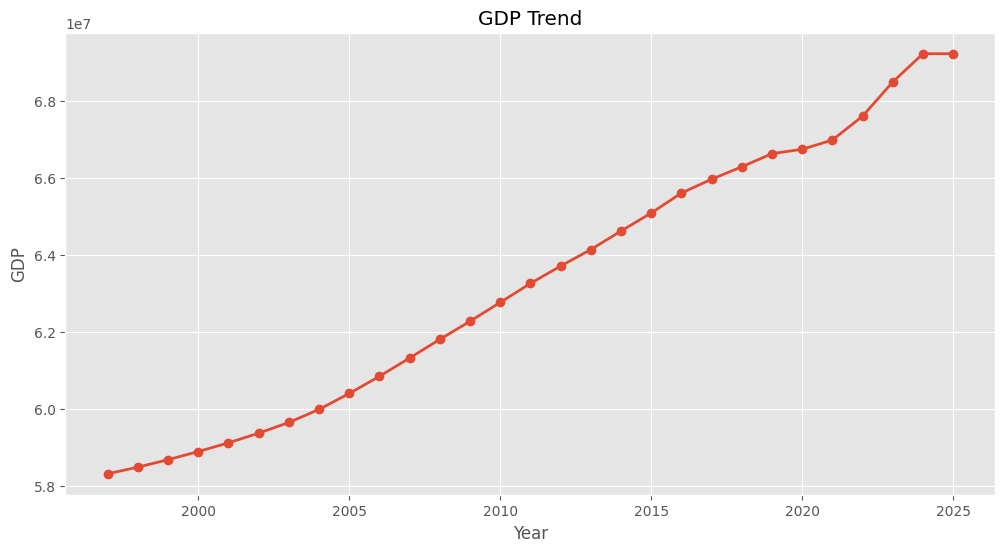

In [24]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["GDP"],
    marker="o",
    linewidth=2
)

plt.title("GDP Trend")

plt.xlabel("Year")

plt.ylabel("GDP")

plt.grid(True)

plt.show()

## **Inflation Trend**

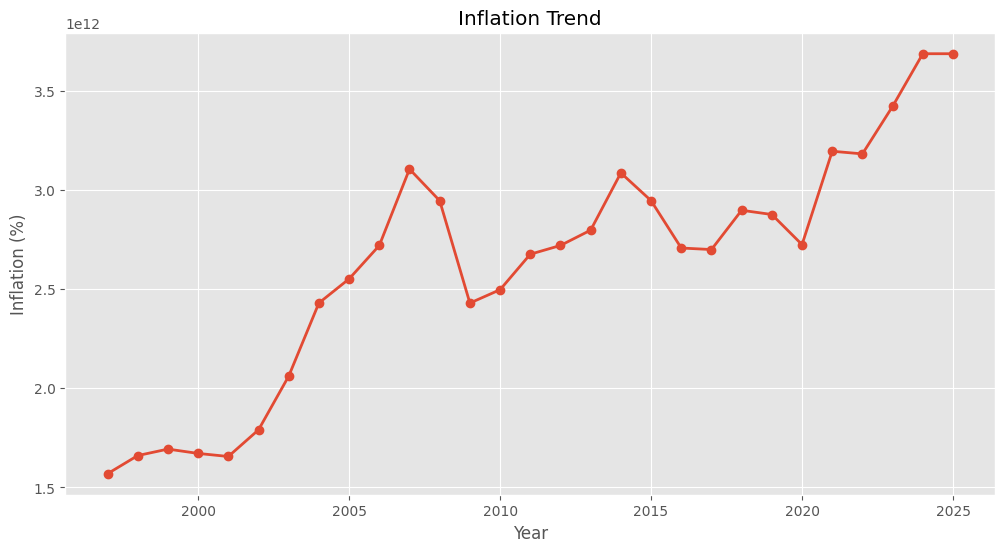

In [25]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Inflation"],
    marker="o",
    linewidth=2
)

plt.title("Inflation Trend")

plt.xlabel("Year")

plt.ylabel("Inflation (%)")

plt.grid(True)

plt.show()

## **Unemployment Trend**

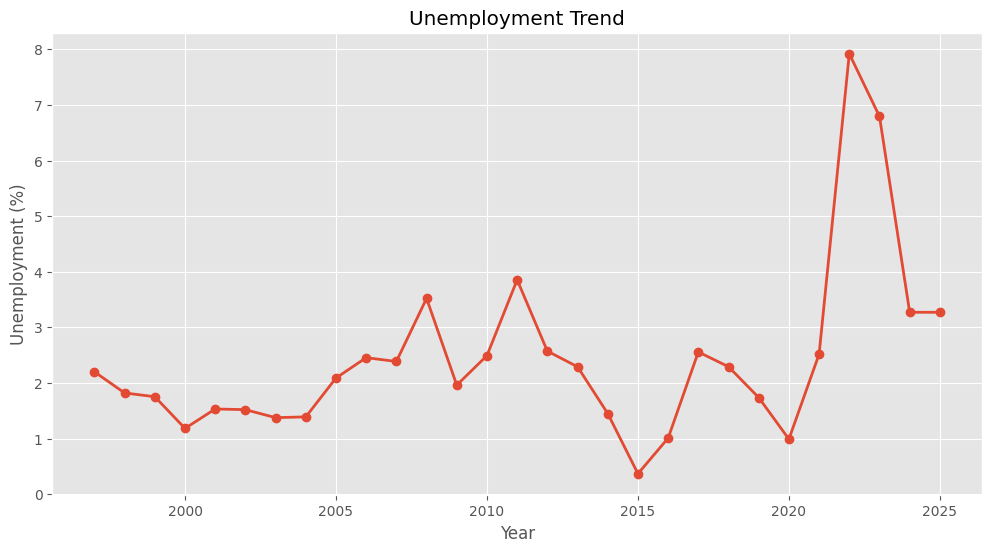

In [26]:
plt.figure(figsize=(12,6))

plt.plot(
    master["Year"],
    master["Unemployment"],
    marker="o",
    linewidth=2
)

plt.title("Unemployment Trend")

plt.xlabel("Year")

plt.ylabel("Unemployment (%)")

plt.grid(True)

plt.show()

## **Distribution of Variables**

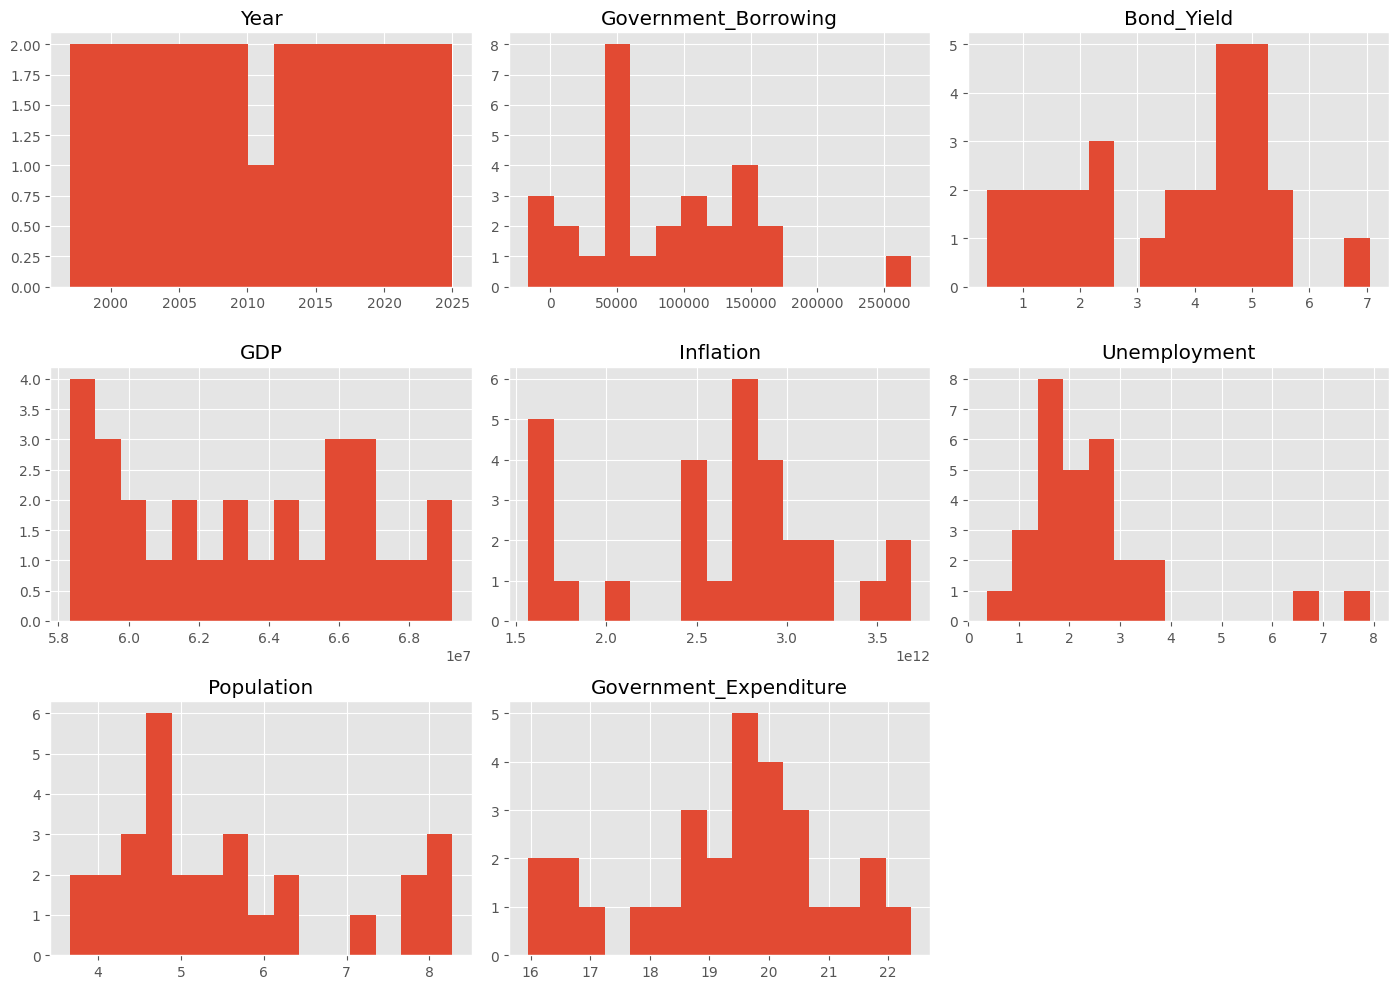

In [27]:
master.hist(
    figsize=(14,10),
    bins=15
)

plt.tight_layout()

plt.show()

## **Boxplots of Numerical Variables**

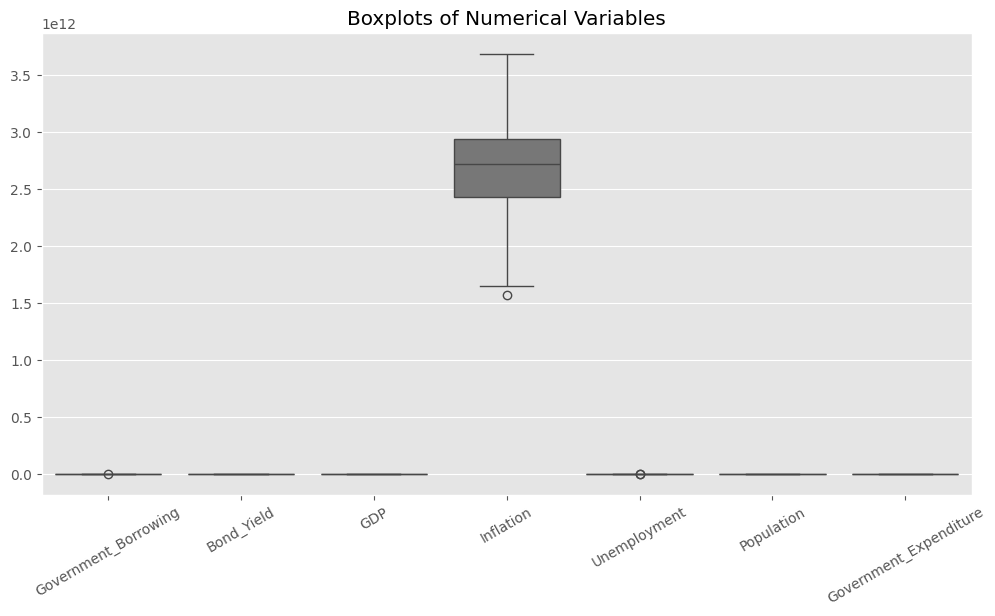

In [28]:
plt.figure(figsize=(12,6))

sns.boxplot(data=master.drop(columns=["Year"]))

plt.xticks(rotation=30)

plt.title("Boxplots of Numerical Variables")

plt.show()

# **Agent-Based Economic Simulation**

## **Simulation Parameters**

In [29]:
# Simulation Settings
NUM_BANKS = 5

NUM_INVESTORS = 20

NUM_HOUSEHOLDS = 100

SIMULATION_STEPS = 50

MONTE_CARLO_RUNS = 100


# Government Economy

INITIAL_GOVERNMENT_DEBT = float(master["Government_Borrowing"].iloc[-1])

INITIAL_BOND_YIELD = float(master["Bond_Yield"].iloc[-1])


# Banks

BANK_INITIAL_CAPITAL = 5000000

BANK_BOND_BUDGET = 1000000


# Investors

INVESTOR_INITIAL_WEALTH = 100000

INVESTOR_RISK_APPETITE = 0.60


# Households

HOUSEHOLD_INITIAL_WEALTH = 50000

HOUSEHOLD_INCOME = 3000

HOUSEHOLD_CONSUMPTION_RATE = 0.70


# Government Policy

NEW_BONDS_PER_STEP = 10000

INTEREST_PAYMENT_RATE = 0.03


print("="*60)
print("Simulation Parameters")
print("="*60)

print("Banks              :", NUM_BANKS)
print("Investors          :", NUM_INVESTORS)
print("Households         :", NUM_HOUSEHOLDS)
print("Simulation Steps   :", SIMULATION_STEPS)
print("Monte Carlo Runs   :", MONTE_CARLO_RUNS)

print()

print("Initial Debt       :", INITIAL_GOVERNMENT_DEBT)
print("Initial Bond Yield :", INITIAL_BOND_YIELD)

Simulation Parameters
Banks              : 5
Investors          : 20
Households         : 100
Simulation Steps   : 50
Monte Carlo Runs   : 100

Initial Debt       : 147593.0
Initial Bond Yield : 4.5833


## **Government Agent**

In [30]:
class GovernmentAgent(Agent):

    def __init__(self):

        self.debt = INITIAL_GOVERNMENT_DEBT

        self.bond_yield = INITIAL_BOND_YIELD

        self.total_bonds = 0

        self.interest_paid = 0

    def issue_bonds(self):

        self.total_bonds += NEW_BONDS_PER_STEP

        self.debt += NEW_BONDS_PER_STEP

    def pay_interest(self):

        self.interest_paid = self.debt * INTEREST_PAYMENT_RATE

        self.debt += self.interest_paid

    def update_bond_yield(self):

        change = np.random.uniform(-0.05,0.05)

        self.bond_yield = max(
            0.1,
            self.bond_yield + change
        )

    def step(self):

        self.issue_bonds()

        self.pay_interest()

        self.update_bond_yield()

## **Bank Agent**

In [31]:
class BankAgent(Agent):

    def __init__(self, bank_id):

        self.bank_id = bank_id

        self.capital = BANK_INITIAL_CAPITAL

        self.bonds_owned = 0

        self.interest_income = 0

    def buy_bonds(self, government):

        # Amount bank invests
        investment = min(
            BANK_BOND_BUDGET,
            self.capital * 0.20
        )

        if investment > 0:

            bonds = investment / 100

            self.bonds_owned += bonds

            self.capital -= investment

            government.debt += investment

            government.total_bonds += bonds

    def receive_interest(self, government):

        self.interest_income = (

            self.bonds_owned

            * government.bond_yield

            / 100

        )

        self.capital += self.interest_income

    def step(self, government):

        self.buy_bonds(government)

        self.receive_interest(government)

In [32]:
# Testing
gov = GovernmentAgent()

bank = BankAgent(1)

print("Capital Before :", bank.capital)

bank.step(gov)

print("Capital After :", bank.capital)

print("Bonds Owned :", bank.bonds_owned)

print("Interest Income :", bank.interest_income)

Capital Before : 5000000
Capital After : 4000458.33
Bonds Owned : 10000.0
Interest Income : 458.3300000000001


## **Investor Agent**

In [33]:
class InvestorAgent(Agent):

    def __init__(self, investor_id):

        self.investor_id = investor_id

        self.wealth = INVESTOR_INITIAL_WEALTH

        self.bonds_owned = 0

        self.interest_income = 0

        self.risk_appetite = np.random.uniform(
            0.30,
            0.90
        )

    def decide_investment(self, government):

        # Investor buys bonds when yield is attractive
        if government.bond_yield > 2:

            investment = self.wealth * self.risk_appetite * 0.20

            self.wealth -= investment

            bonds = investment / 100

            self.bonds_owned += bonds

            government.debt += investment

            government.total_bonds += bonds

    def receive_interest(self, government):

        self.interest_income = (

            self.bonds_owned *

            government.bond_yield /

            100

        )

        self.wealth += self.interest_income

    def step(self, government):

        self.decide_investment(government)

        self.receive_interest(government)

In [34]:
# Testing

gov = GovernmentAgent()

investor = InvestorAgent(1)

print("Initial Wealth :", investor.wealth)

investor.step(gov)

print("Updated Wealth :", investor.wealth)

print("Bonds Owned :", investor.bonds_owned)

print("Interest Income :", investor.interest_income)

Initial Wealth : 100000
Updated Wealth : 93954.67642162823
Bonds Owned : 60.480956020290456
Interest Income : 2.7720236572779724


## **Household Agent**

In [35]:
class HouseholdAgent(Agent):

    def __init__(self, household_id):

        self.household_id = household_id

        self.wealth = HOUSEHOLD_INITIAL_WEALTH

        self.income = HOUSEHOLD_INCOME

        self.savings = 0

        self.consumption = 0

    def earn_income(self):

        self.wealth += self.income

    def consume(self):

        self.consumption = (

            self.income *

            HOUSEHOLD_CONSUMPTION_RATE

        )

        self.wealth -= self.consumption

    def save(self):

        self.savings = (

            self.income *

            (1 - HOUSEHOLD_CONSUMPTION_RATE)

        )

        self.wealth += self.savings

    def invest(self, government):

        # Investing 10% of savings into government bonds

        investment = self.savings * 0.10

        if investment > 0:

            self.wealth -= investment

            government.debt += investment

            government.total_bonds += investment / 100

    def step(self, government):

        self.earn_income()

        self.consume()

        self.save()

        self.invest(government)

In [36]:
# Testing

gov = GovernmentAgent()

house = HouseholdAgent(1)

print("Initial Wealth :", house.wealth)

house.step(gov)

print("Updated Wealth :", house.wealth)

print("Savings :", house.savings)

print("Consumption :", house.consumption)

Initial Wealth : 50000
Updated Wealth : 51710.0
Savings : 900.0000000000001
Consumption : 2100.0


## **UK Debt Simulation Model**

In [37]:
class UKDebtModel(Model):

    def __init__(self):

        # Creating Government
        self.government = GovernmentAgent()

        # Creating Banks
        self.banks = [
            BankAgent(i)
            for i in range(NUM_BANKS)
        ]

        # Creating Investors
        self.investors = [
            InvestorAgent(i)
            for i in range(NUM_INVESTORS)
        ]

        # Creating Households
        self.households = [
            HouseholdAgent(i)
            for i in range(NUM_HOUSEHOLDS)
        ]

        # History Lists
        self.debt_history = []

        self.yield_history = []

        self.bank_capital_history = []

        self.household_wealth_history = []

        self.investor_wealth_history = []


    def step(self):

        # -------------------------------
        # Government
        # -------------------------------
        self.government.step()

        # -------------------------------
        # Banks
        # -------------------------------
        for bank in self.banks:

            bank.step(self.government)

        # -------------------------------
        # Investors
        # -------------------------------
        for investor in self.investors:

            investor.step(self.government)

        # -------------------------------
        # Households
        # -------------------------------
        for house in self.households:

            house.step(self.government)

        # -------------------------------
        # Store Results
        # -------------------------------

        self.debt_history.append(
            self.government.debt
        )

        self.yield_history.append(
            self.government.bond_yield
        )

        self.bank_capital_history.append(

            np.mean(

                [b.capital for b in self.banks]

            )

        )

        self.household_wealth_history.append(

            np.mean(

                [h.wealth for h in self.households]

            )

        )

        self.investor_wealth_history.append(

            np.mean(

                [i.wealth for i in self.investors]

            )

        )

## **Simulation Execution**

In [38]:
model = UKDebtModel()

for _ in range(SIMULATION_STEPS):

    model.step()

print("Simulation Completed Successfully")

print()

print("Final Government Debt :")
print(model.government.debt)

print()

print("Final Bond Yield :")
print(model.government.bond_yield)

print()

print("Average Household Wealth :")
print(np.mean(model.household_wealth_history))

print()

print("Average Investor Wealth :")
print(np.mean(model.investor_wealth_history))

print()

print("Average Bank Capital :")
print(np.mean(model.bank_capital_history))

Simulation Completed Successfully

Final Government Debt :
106150175.15513413

Final Bond Yield :
4.744075111865489

Average Household Wealth :
93605.0

Average Investor Wealth :
14803.843079057939

Average Bank Capital :
409764.5702213909


## **Government Debt During Simulation**

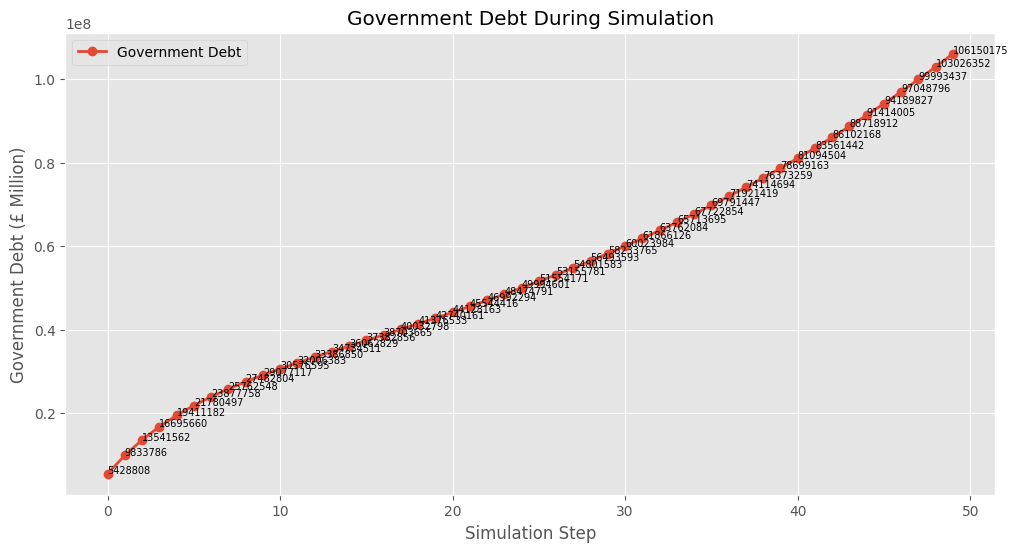

In [39]:
plt.figure(figsize=(12,6))

plt.plot(
    model.debt_history,
    marker="o",
    linewidth=2,
    label="Government Debt"
)

for i, value in enumerate(model.debt_history):

    plt.text(
        i,
        value,
        f"{value:.0f}",
        fontsize=7
    )

plt.title("Government Debt During Simulation")

plt.xlabel("Simulation Step")

plt.ylabel("Government Debt (£ Million)")

plt.grid(True)

plt.legend()

plt.show()

## **Bond Yield During Simulation**

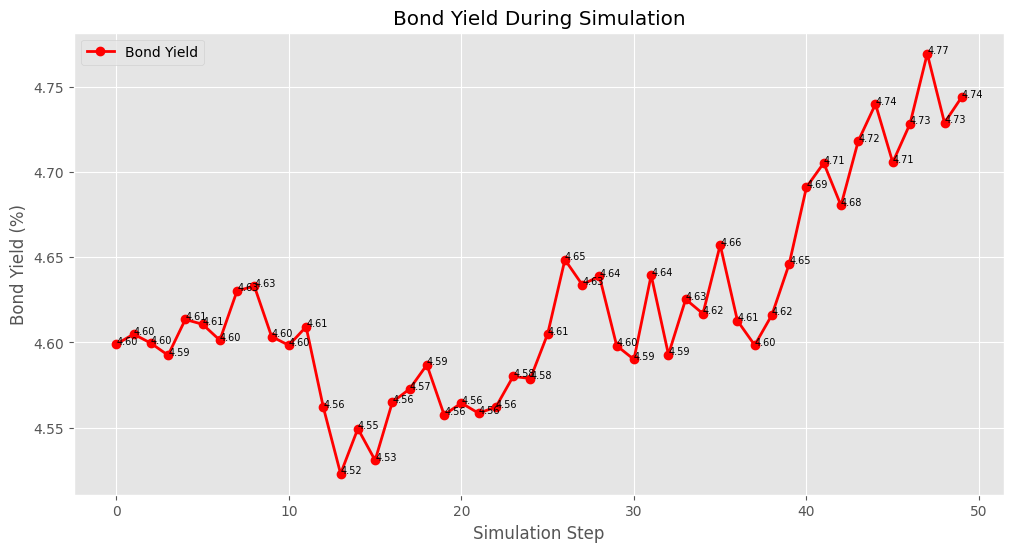

In [40]:
plt.figure(figsize=(12,6))

plt.plot(
    model.yield_history,
    marker="o",
    color="red",
    linewidth=2,
    label="Bond Yield"
)

for i, value in enumerate(model.yield_history):

    plt.text(
        i,
        value,
        f"{value:.2f}",
        fontsize=7
    )

plt.title("Bond Yield During Simulation")

plt.xlabel("Simulation Step")

plt.ylabel("Bond Yield (%)")

plt.grid(True)

plt.legend()

plt.show()

## **Average Household Wealth**

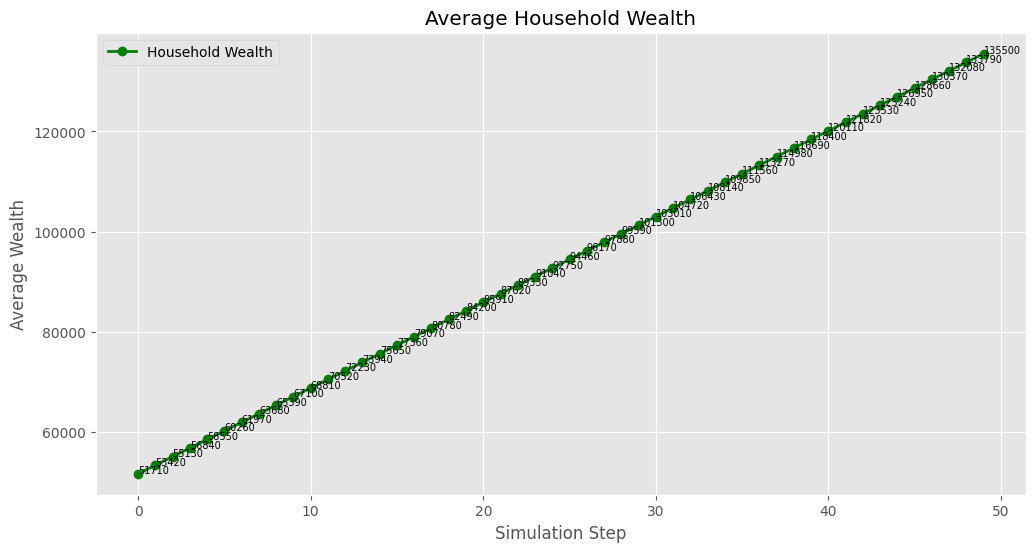

In [41]:
plt.figure(figsize=(12,6))

plt.plot(
    model.household_wealth_history,
    marker="o",
    color="green",
    linewidth=2,
    label="Household Wealth"
)

for i, value in enumerate(model.household_wealth_history):

    plt.text(
        i,
        value,
        f"{value:.0f}",
        fontsize=7
    )

plt.title("Average Household Wealth")

plt.xlabel("Simulation Step")

plt.ylabel("Average Wealth")

plt.grid(True)

plt.legend()

plt.show()

## **Average Investor Wealth**

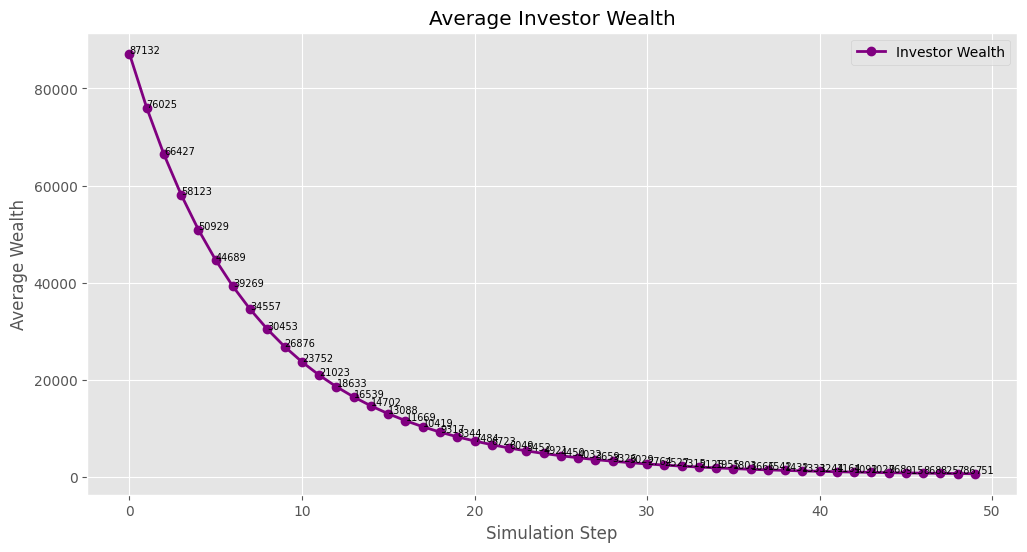

In [42]:
plt.figure(figsize=(12,6))

plt.plot(
    model.investor_wealth_history,
    marker="o",
    color="purple",
    linewidth=2,
    label="Investor Wealth"
)

for i, value in enumerate(model.investor_wealth_history):

    plt.text(
        i,
        value,
        f"{value:.0f}",
        fontsize=7
    )

plt.title("Average Investor Wealth")

plt.xlabel("Simulation Step")

plt.ylabel("Average Wealth")

plt.grid(True)

plt.legend()

plt.show()

## **Average Bank Capital**

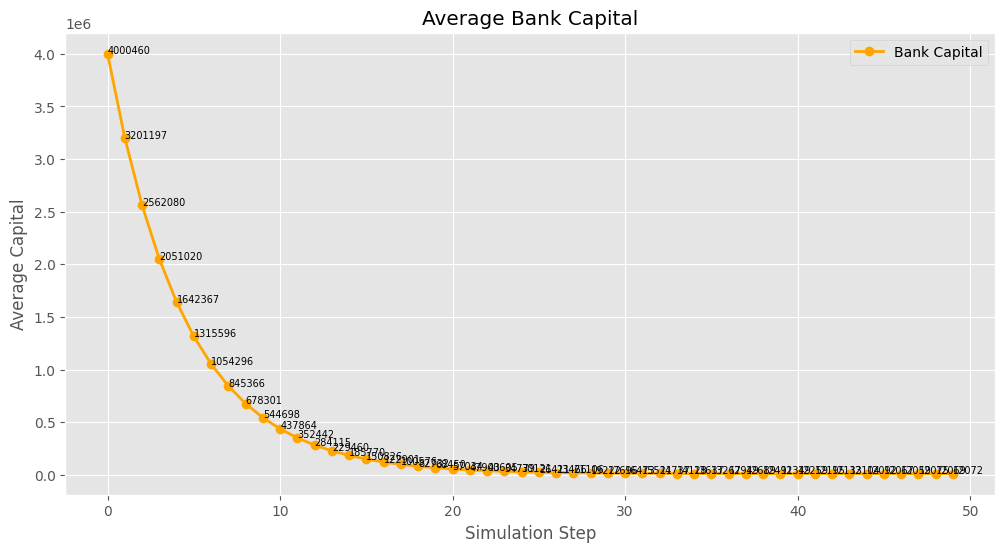

In [43]:
plt.figure(figsize=(12,6))

plt.plot(
    model.bank_capital_history,
    marker="o",
    color="orange",
    linewidth=2,
    label="Bank Capital"
)

for i, value in enumerate(model.bank_capital_history):

    plt.text(
        i,
        value,
        f"{value:.0f}",
        fontsize=7
    )

plt.title("Average Bank Capital")

plt.xlabel("Simulation Step")

plt.ylabel("Average Capital")

plt.grid(True)

plt.legend()

plt.show()

# **Monte Carlo Simulation**

## **Monte Carlo Simulation**

In [44]:
simulation_results = []

for run in range(MONTE_CARLO_RUNS):

    model = UKDebtModel()

    for step in range(SIMULATION_STEPS):

        model.step()

    simulation_results.append({

        "Run": run + 1,

        "Government_Debt": model.debt_history[-1],

        "Bond_Yield": model.yield_history[-1],

        "Household_Wealth": model.household_wealth_history[-1],

        "Investor_Wealth": model.investor_wealth_history[-1],

        "Bank_Capital": model.bank_capital_history[-1]

    })

simulation_results = pd.DataFrame(simulation_results)

display(simulation_results.head())

print("Simulation Runs Completed :", len(simulation_results))

,Run,Government_Debt,Bond_Yield,Household_Wealth,Investor_Wealth,Bank_Capital
0,1,1.059725e+08,4.291874,135500.0,1034.477843,11034.172619
1,2,1.061360e+08,4.442671,135500.0,840.701310,11416.894426
2,3,1.059473e+08,4.335900,135500.0,1164.282603,11210.277029
3,4,1.059747e+08,4.741029,135500.0,1327.173076,12104.795254
4,5,1.059356e+08,4.468823,135500.0,1399.053480,11397.574898


Simulation Runs Completed : 100


## **Simulation Summary Statistics**

In [45]:
summary = simulation_results.describe()

display(summary)

summary.to_csv(
    "MonteCarlo_Summary.csv",
    index=True
)

,Run,Government_Debt,Bond_Yield,Household_Wealth,Investor_Wealth,Bank_Capital
count,100.000000,1.000000e+02,100.000000,100.0,100.000000,100.000000
mean,50.500000,1.060050e+08,4.572641,135500.0,1112.679711,11689.709233
std,29.011492,1.181236e+05,0.187742,0.0,268.481896,443.460343
min,1.000000,1.057628e+08,4.220992,135500.0,552.362146,10882.025427
25%,25.750000,1.059351e+08,4.426734,135500.0,898.826378,11360.960881
50%,50.500000,1.059901e+08,4.579259,135500.0,1145.962470,11692.523847
75%,75.250000,1.060933e+08,4.714182,135500.0,1305.725603,11999.976903
max,100.000000,1.062811e+08,5.016542,135500.0,1642.733699,12740.716993


## **Average Simulation Results**

In [46]:
print("Average Government Debt :")

print(simulation_results["Government_Debt"].mean())

print()

print("Average Bond Yield :")

print(simulation_results["Bond_Yield"].mean())

print()

print("Average Household Wealth :")

print(simulation_results["Household_Wealth"].mean())

print()

print("Average Investor Wealth :")

print(simulation_results["Investor_Wealth"].mean())

print()

print("Average Bank Capital :")

print(simulation_results["Bank_Capital"].mean())

Average Government Debt :
106004951.68962556

Average Bond Yield :
4.572640991287887

Average Household Wealth :
135500.0

Average Investor Wealth :
1112.6797110532648

Average Bank Capital :
11689.70923337195


## **Confidence Interval Analysis**

In [47]:
confidence = 0.95

for column in simulation_results.columns[1:]:

    mean = simulation_results[column].mean()

    sem = stats.sem(simulation_results[column])

    ci = stats.t.interval(

        confidence,

        len(simulation_results)-1,

        loc=mean,

        scale=sem

    )

    print("="*60)

    print(column)

    print("Mean :", mean)

    print("95% Confidence Interval :", ci)

Government_Debt
Mean : 106004951.68962556
95% Confidence Interval : (np.float64(105981513.40371263), np.float64(106028389.97553849))
Bond_Yield
Mean : 4.572640991287887
95% Confidence Interval : (np.float64(4.535388815645546), np.float64(4.609893166930228))
Household_Wealth
Mean : 135500.0
95% Confidence Interval : (np.float64(nan), np.float64(nan))
Investor_Wealth
Mean : 1112.6797110532648
95% Confidence Interval : (np.float64(1059.407078159225), np.float64(1165.9523439473046))
Bank_Capital
Mean : 11689.70923337195
95% Confidence Interval : (np.float64(11601.717080391616), np.float64(11777.701386352284))


## **Monte Carlo Visualisation**

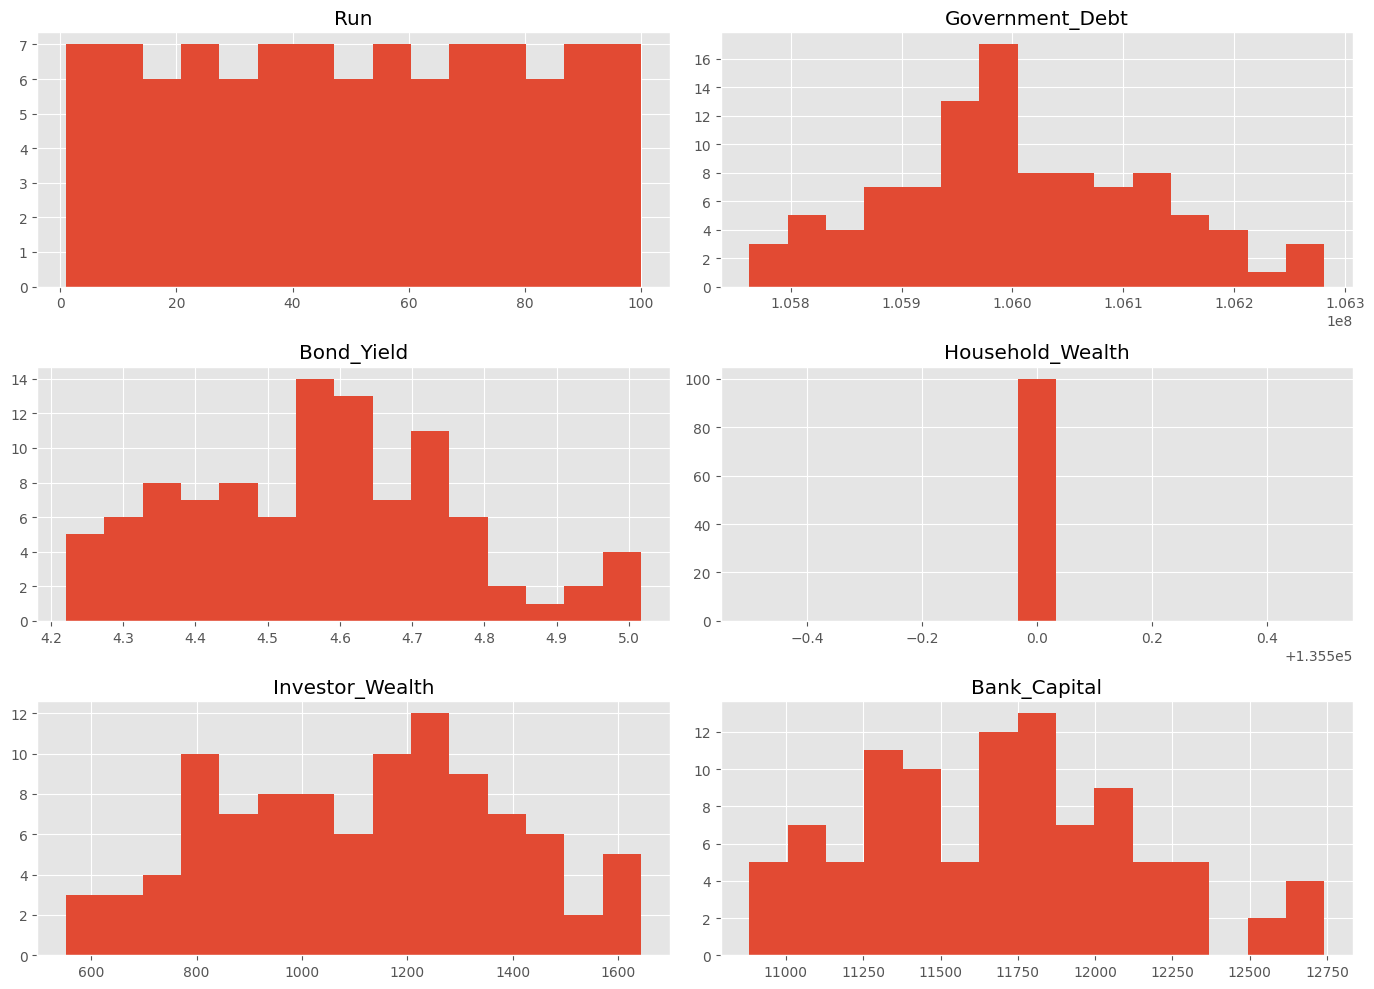

In [48]:
simulation_results.hist(

    figsize=(14,10),

    bins=15

)

plt.tight_layout()

plt.show()

## **Normalized Monte Carlo Results**

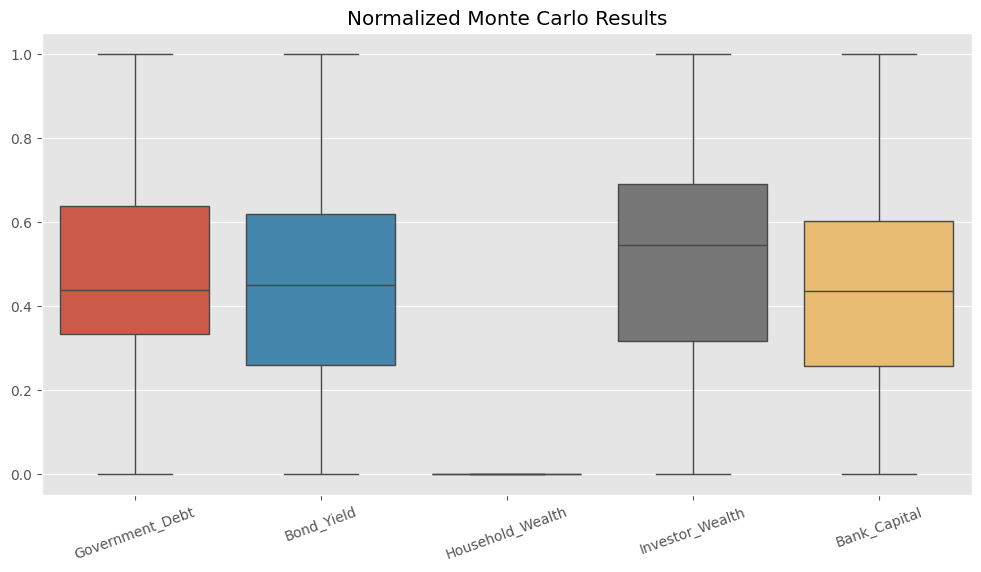

In [49]:
from sklearn.preprocessing import MinMaxScaler

scaled = pd.DataFrame(
    MinMaxScaler().fit_transform(
        simulation_results.drop(columns=["Run"])
    ),
    columns=simulation_results.columns[1:]
)

plt.figure(figsize=(12,6))

sns.boxplot(data=scaled)

plt.title("Normalized Monte Carlo Results")

plt.xticks(rotation=20)

plt.show()

# **Network Analysis of Economic Agents**

## **Economic Network Construction**

In [50]:
G = nx.Graph()

# Adding Government
G.add_node("Government", node_type="Government")

# Adding Banks
for i in range(NUM_BANKS):

    G.add_node(f"Bank_{i+1}", node_type="Bank")

# Adding Investors
for i in range(NUM_INVESTORS):

    G.add_node(f"Investor_{i+1}", node_type="Investor")

# Adding Households
for i in range(NUM_HOUSEHOLDS):

    G.add_node(f"Household_{i+1}", node_type="Household")

print("Total Nodes :", G.number_of_nodes())
print("Total Edges :", G.number_of_edges())

Total Nodes : 126
Total Edges : 0


In [51]:
# Government <-> Banks

for i in range(NUM_BANKS):

    G.add_edge("Government", f"Bank_{i+1}")


# Government <-> Investors

for i in range(NUM_INVESTORS):

    G.add_edge("Government", f"Investor_{i+1}")


# Government <-> Households

for i in range(NUM_HOUSEHOLDS):

    G.add_edge("Government", f"Household_{i+1}")

print("Edges Created :", G.number_of_edges())

Edges Created : 125


## **Network Visualisation**

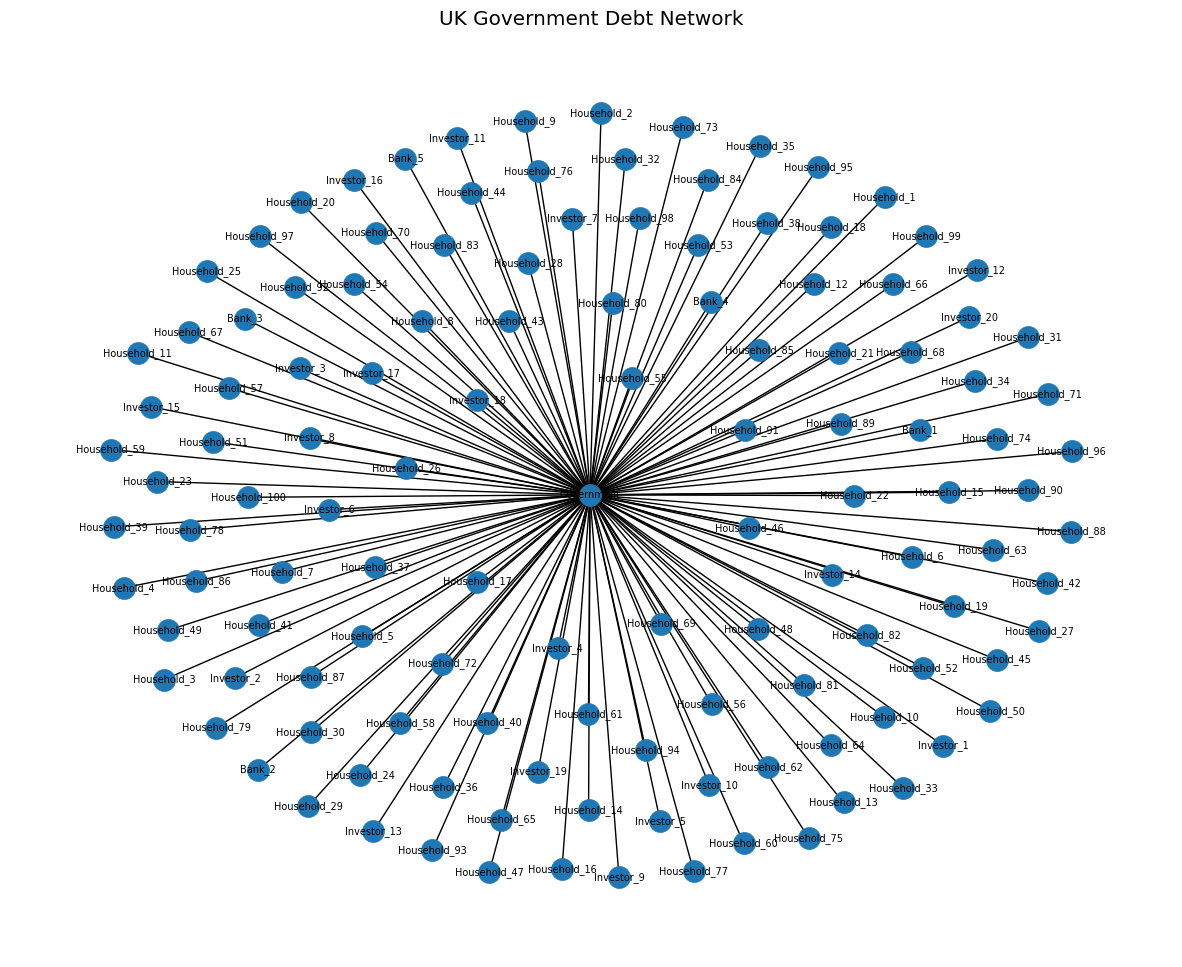

In [52]:
plt.figure(figsize=(15,12))

pos = nx.spring_layout(
    G,
    seed=42
)

nx.draw_networkx(

    G,

    pos,

    node_size=250,

    font_size=7,

    with_labels=True

)

plt.title("UK Government Debt Network")

plt.axis("off")

plt.show()

## **Centrality Analysis**

In [53]:
degree = nx.degree_centrality(G)

degree_df = pd.DataFrame({

    "Node": degree.keys(),

    "Degree_Centrality": degree.values()

})

degree_df = degree_df.sort_values(

    "Degree_Centrality",

    ascending=False

)

display(degree_df.head(20))

,Node,Degree_Centrality
0,Government,1.000
1,Bank_1,0.008
2,Bank_2,0.008
3,Bank_3,0.008
4,Bank_4,0.008
5,Bank_5,0.008
6,Investor_1,0.008
7,Investor_2,0.008
8,Investor_3,0.008
9,Investor_4,0.008


In [54]:
between = nx.betweenness_centrality(G)

between_df = pd.DataFrame({

    "Node": between.keys(),

    "Betweenness": between.values()

})

between_df = between_df.sort_values(

    "Betweenness",

    ascending=False

)

display(between_df.head(20))

,Node,Betweenness
0,Government,1.0
1,Bank_1,0.0
2,Bank_2,0.0
3,Bank_3,0.0
4,Bank_4,0.0
5,Bank_5,0.0
6,Investor_1,0.0
7,Investor_2,0.0
8,Investor_3,0.0
9,Investor_4,0.0


In [55]:
close = nx.closeness_centrality(G)

close_df = pd.DataFrame({

    "Node": close.keys(),

    "Closeness": close.values()

})

close_df = close_df.sort_values(

    "Closeness",

    ascending=False

)

display(close_df.head(20))

,Node,Closeness
0,Government,1.000000
1,Bank_1,0.502008
2,Bank_2,0.502008
3,Bank_3,0.502008
4,Bank_4,0.502008
5,Bank_5,0.502008
6,Investor_1,0.502008
7,Investor_2,0.502008
8,Investor_3,0.502008
9,Investor_4,0.502008


## **Network Comparison**

In [56]:
centrality = degree_df.merge(

    between_df,

    on="Node"

)

centrality = centrality.merge(

    close_df,

    on="Node"

)

display(centrality.head(20))

,Node,Degree_Centrality,Betweenness,Closeness
0,Government,1.000,1.0,1.000000
1,Bank_1,0.008,0.0,0.502008
2,Bank_2,0.008,0.0,0.502008
3,Bank_3,0.008,0.0,0.502008
4,Bank_4,0.008,0.0,0.502008
5,Bank_5,0.008,0.0,0.502008
6,Investor_1,0.008,0.0,0.502008
7,Investor_2,0.008,0.0,0.502008
8,Investor_3,0.008,0.0,0.502008
9,Investor_4,0.008,0.0,0.502008


## **Most Influential Economic Agents**

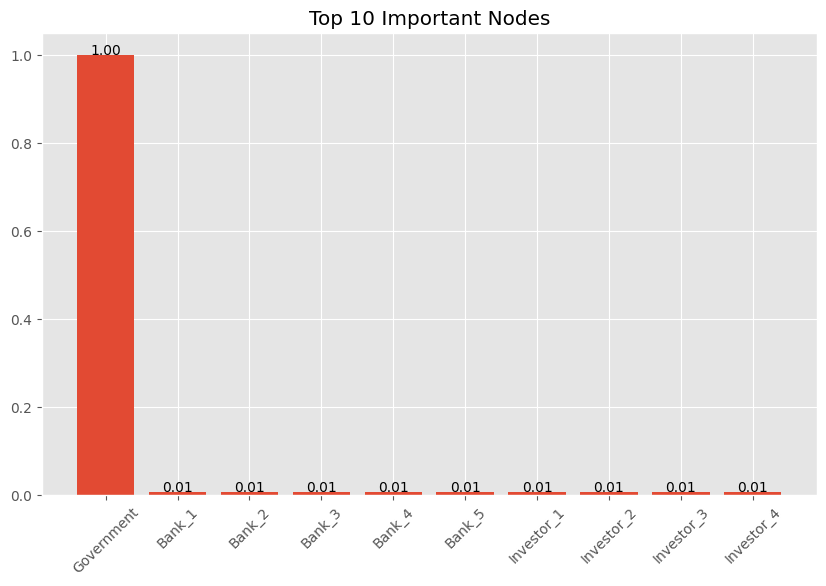

In [57]:
top = centrality.sort_values(

    "Degree_Centrality",

    ascending=False

).head(10)

plt.figure(figsize=(10,6))

bars = plt.bar(

    top["Node"],

    top["Degree_Centrality"]

)

plt.title("Top 10 Important Nodes")

plt.xticks(rotation=45)

for bar in bars:

    y = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        y,

        f"{y:.2f}",

        ha="center"

    )

plt.show()

In [58]:
simulation_results.to_csv("simulation_results.csv", index=False)